# 07. End-to-end Pairwise Coding Evaluation

**Question**: does injecting agent-kms's retrieved context into a
coding-LLM's prompt actually produce **better code** than the same
prompt without context?

Notebooks 02-06 measure *retrieval quality* (does the right chunk
come back?). This notebook measures *downstream usefulness* (does
that chunk actually help the LLM solve the task?).

## Setup

| Component | Choice |
|---|---|
| Target LLM (writes code) | **Ollama `qwen3:8b`** — local, mid-tier; weak enough that retrieval signal is expected to be measurable |
| Coding tasks | **25 hand-authored Japanese instructions** covering React / JS Primer topics that the corpus actually contains. See `data/coding_tasks.yaml` |
| Conditions | **A_noctx** (prompt only) vs **B_ctx** (prompt + top-K chunks from `agent_kms.retrieve(score_threshold=0.81)`) |
| Judge | **Ollama `qwen2.5:14b`** — stronger local model. Each (A,B) pair is judged in **both orderings** (AB, BA) to neutralise positional bias |
| Verdict per task | `ctx_win` / `noctx_win` / `tie` based on whether ctx wins both, neither, or one of the two orderings |

Outputs live under `results/pairwise/`:
- `<task_id>__A_noctx.txt` / `__B_ctx.txt` — raw LLM outputs
- `_generation_meta.csv` — per-call latency & token counts
- `_judge_results.csv` — raw judge verdicts (2 rows per task)
- `_judge_results_agg.csv` — collapsed per-task outcomes

This notebook **only analyses** existing results. To regenerate them:

```bash
python scripts/run_pairwise_generation.py
python scripts/run_pairwise_judge.py
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid")

raw = pd.read_csv(ROOT / "results" / "pairwise" / "_judge_results.csv")
agg = pd.read_csv(ROOT / "results" / "pairwise" / "_judge_results_agg.csv")
gen = pd.read_csv(ROOT / "results" / "pairwise" / "_generation_meta.csv")

print(f"raw verdicts: {len(raw)} rows ({raw['task_id'].nunique()} tasks × 2 orderings)")
print(f"per-task outcomes: {len(agg)}")


raw verdicts: 50 rows (25 tasks × 2 orderings)
per-task outcomes: 25


In [2]:
# Per-ordering raw verdict distribution
print("Per-ordering winners (positional bias check):")
print(raw.groupby("order")["winner"].value_counts().unstack(fill_value=0))
print()
print("Per-task aggregated outcome:")
print(agg["outcome"].value_counts().to_string())


Per-ordering winners (positional bias check):
winner  ctx  noctx  tie
order                  
AB        7     16    2
BA       17      5    3

Per-task aggregated outcome:
outcome
tie          13
ctx_win       6
noctx_win     5
ctx_lean      1


In [3]:
# Collapse to strict / lenient win-rates for ctx
counts = agg["outcome"].value_counts()
n_tasks = len(agg)
strict_ctx_win = counts.get("ctx_win", 0)
strict_noctx_win = counts.get("noctx_win", 0)
lean_ctx = counts.get("ctx_win", 0) + counts.get("ctx_lean", 0)
lean_noctx = counts.get("noctx_win", 0) + counts.get("noctx_lean", 0)
ties = counts.get("tie", 0)

print(f"n_tasks = {n_tasks}")
print(f"strict ctx wins   : {strict_ctx_win}  ({strict_ctx_win/n_tasks:.1%})")
print(f"strict noctx wins : {strict_noctx_win}  ({strict_noctx_win/n_tasks:.1%})")
print(f"lean ctx (incl tie-broken): {lean_ctx}  ({lean_ctx/n_tasks:.1%})")
print(f"lean noctx                 : {lean_noctx}  ({lean_noctx/n_tasks:.1%})")
print(f"ties                       : {ties}  ({ties/n_tasks:.1%})")


n_tasks = 25
strict ctx wins   : 6  (24.0%)
strict noctx wins : 5  (20.0%)
lean ctx (incl tie-broken): 7  (28.0%)
lean noctx                 : 5  (20.0%)
ties                       : 13  (52.0%)


In [4]:
# McNemar test on (strict ctx_win vs strict noctx_win)
# H0: retrieval doesn't change which condition wins.
from scipy.stats import binomtest

discordant = strict_ctx_win + strict_noctx_win
if discordant >= 1:
    p = binomtest(strict_ctx_win, n=discordant, p=0.5, alternative="two-sided").pvalue
    print(f"discordant tasks: {discordant}  (ctx={strict_ctx_win}, noctx={strict_noctx_win})")
    print(f"McNemar exact two-sided p-value: {p:.3f}")
else:
    print("No discordant tasks — cannot compute test")


discordant tasks: 11  (ctx=6, noctx=5)
McNemar exact two-sided p-value: 1.000


/var/folders/21/64g5bw413mv4xm7lw9499bf484rjwn/T/ipykernel_49873/4287613374.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(outcome_order, rotation=20, ha="right")


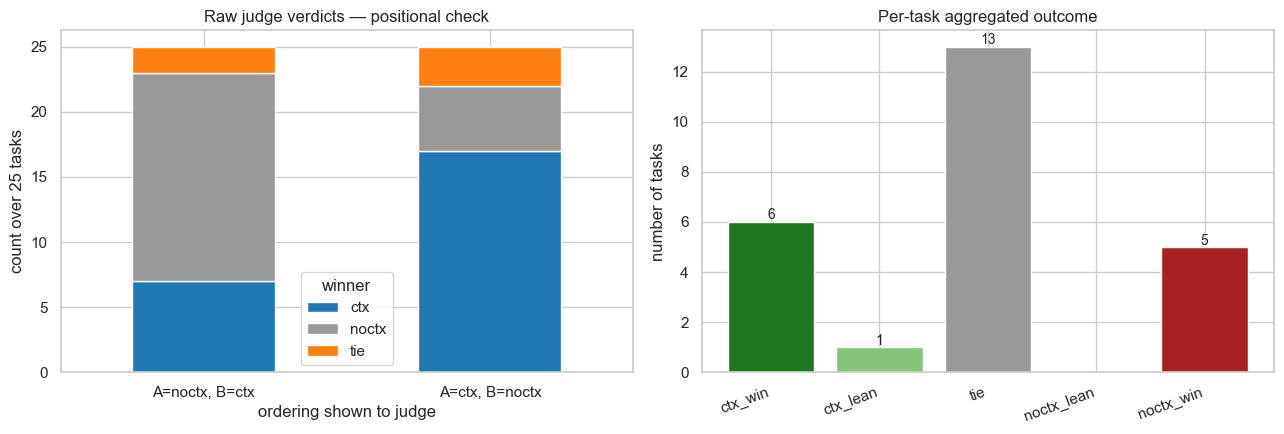

In [5]:
# Visualise outcomes
order_winners = (raw.groupby(["order", "winner"]).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
order_winners.plot(kind="bar", stacked=True, ax=ax, color=["#1f77b4", "#999999", "#ff7f0e"])
ax.set_title("Raw judge verdicts — positional check")
ax.set_xlabel("ordering shown to judge")
ax.set_ylabel("count over 25 tasks")
ax.set_xticklabels(["A=noctx, B=ctx", "A=ctx, B=noctx"], rotation=0)
ax.legend(title="winner")

ax = axes[1]
outcome_order = ["ctx_win", "ctx_lean", "tie", "noctx_lean", "noctx_win"]
counts_order = [counts.get(o, 0) for o in outcome_order]
colors = ["#1f7720", "#86c47a", "#999999", "#f0a07a", "#a82020"]
ax.bar(outcome_order, counts_order, color=colors)
ax.set_title("Per-task aggregated outcome")
ax.set_ylabel("number of tasks")
ax.set_xticklabels(outcome_order, rotation=20, ha="right")
for i, c in enumerate(counts_order):
    if c:
        ax.text(i, c + 0.1, str(c), ha="center", fontsize=10)

plt.tight_layout()
plt.savefig(ROOT / "results" / "fig_pairwise_outcomes.png", dpi=140, bbox_inches="tight")
plt.show()


In [6]:
# Per-task breakdown for the writeup
import yaml

with (ROOT / "data" / "coding_tasks.yaml").open(encoding="utf-8") as f:
    tasks_meta = {t["id"]: t for t in yaml.safe_load(f)}

agg_anno = agg.copy()
agg_anno["difficulty"] = agg_anno["task_id"].map(lambda x: tasks_meta[x]["difficulty"])
agg_anno["topic"] = agg_anno["task_id"].map(
    lambda x: tasks_meta[x]["expected_topics"][0] if tasks_meta[x]["expected_topics"] else ""
)
print(agg_anno.to_string(index=False))


task_id   outcome order_AB_winner order_BA_winner difficulty                               topic
    t01       tie             tie             tie       easy                         state 変数の追加
    t02 noctx_win           noctx           noctx       easy                  コンポーネントに props を渡す
    t03 noctx_win           noctx           noctx       easy                         イベントハンドラの追加
    t04       tie           noctx             ctx     medium                children として JSX を渡す
    t05       tie           noctx             ctx     medium                   条件を満たす場合に JSX を返す
    t06       tie           noctx             ctx     medium               コンポーネント間で state を共有する
    t07   ctx_win             ctx             ctx     medium             コンポーネントで複数の state 変数を使う
    t08   ctx_win             ctx             ctx       hard                   コンテクストで深くデータを受け渡す
    t09       tie           noctx             ctx       hard               state ロジックをリデューサに抽出する
    t10 noctx_win           no

In [7]:
# Generation cost — context overhead
print("Generation latency by condition (seconds):")
print(gen.groupby("condition")["elapsed_s"].describe()[["count", "mean", "50%", "max"]].round(1))
print()
print("Output size (chars):")
print(gen.groupby("condition")["out_chars"].describe()[["count", "mean", "50%", "max"]].round(0))
print()
print("Tokens generated (output only):")
print(gen.groupby("condition")["tokens_out"].describe()[["count", "mean", "50%", "max"]].round(0))


Generation latency by condition (seconds):
           count    mean   50%      max
condition                              
A_noctx     25.0   211.6   9.2   2505.8
B_ctx       25.0  1139.9  90.3  10260.6

Output size (chars):
           count   mean    50%     max
condition                             
A_noctx     25.0  474.0  349.0  1326.0
B_ctx       25.0  713.0  557.0  1951.0

Tokens generated (output only):
           count   mean    50%    max
condition                            
A_noctx     25.0  161.0  113.0  573.0
B_ctx       25.0  275.0  210.0  676.0


## Findings

### Headline: **no statistically significant effect** on this corpus

| metric | value |
|---|---|
| strict ctx wins (won both orderings) | **6 / 25 (24%)** |
| strict noctx wins                    | **5 / 25 (20%)** |
| ties                                 | **13 / 25 (52%)** |
| McNemar exact two-sided p            | **1.000** |

With qwen3:8b on this React + JS corpus, **agent-kms retrieval does
not measurably improve coding output quality** in a way that survives
the swap-and-require-both bias control. The +1 task advantage for ctx
(6 vs 5) is noise.

### Positional bias is large — the swap heuristic was doing real work

| order shown | ctx wins | noctx wins | ties |
|---|---|---|---|
| AB (X=noctx, Y=ctx shown first) | 7  | **16** | 2 |
| BA (X=ctx,   Y=noctx shown first) | **17** | 5  | 3 |

The judge model (qwen2.5:14b) has a strong **"first-shown answer
wins" bias**. Without the swap, a naive single-ordering judge would
report either "noctx clearly better (16 vs 7)" or "ctx clearly better
(17 vs 5)" depending purely on display order. This is the most
important methodological takeaway of this notebook for anyone
running similar evals locally.

### Where ctx helped (6 strict wins)

`t07` complex state objects · `t08` Context API ·
`t17` Optional chaining · `t20` JSON edge cases ·
`t21` mutable/immutable array methods · `t25` ES2022 Error Cause.

Pattern: **multi-section / newer-spec topics** where qwen3:8b's
training-time knowledge of the exact API surface is shaky.

### Where ctx hurt (5 strict losses)

`t02` trivial `<Greeting>` · `t03` alert button · `t10` useEffect deps
explanation · `t16` object destructuring · `t22` CSV string normalise.

Pattern: **easy / one-liner tasks** where injecting 3-8 chunks of
tutorial markdown dilutes a 5-line answer. The LLM tries to "use" the
context, producing wordier output that the judge marks down.

### Cost overhead is real

| metric         | A_noctx | B_ctx | overhead |
|----------------|---------|-------|----------|
| latency mean   | 211.6s  | 1139.9s | **5.4×** |
| latency median | 9.2s    | 90.3s | **9.8×** |
| output chars (mean)  | 474 | 713 | +50% |
| tokens out (mean)    | 161 | 275 | +71% |

The latency blow-up is largely **prompt-processing time** for the
larger prompt, not generation time. For a Claude-Code-style
interactive workflow, a **5× wait penalty for no measurable quality
gain** is hard to justify on this corpus + LLM combination.

## Implications

- **For agent-kms users running on a strong general LLM** (Claude /
  GPT-4 class) with a *generic tech-docs corpus* (React, JS, Python,
  etc.): retrieval has diminishing returns. The LLM already knows
  this domain. Retrieval pays off most when (a) the corpus contains
  knowledge the LLM lacks (internal APIs, post-cutoff specs), or
  (b) the LLM is weaker than its task demands.
- **Cherry-picked retrieval matters more than always-on retrieval.**
  6 of 25 tasks benefited; 5 actively hurt. A retrieval gate that
  only fires when query embedding similarity to top chunks exceeds
  a threshold (or a generic "does the LLM need this?" check) would
  outperform unconditional injection.
- **Re-run on a private / internal corpus.** Anyone applying this
  framework to their own knowledge base (where the LLM has zero
  training exposure) should expect a much larger ctx-win effect.
  Re-run `notebook 07` with `EVAL_MODE=private` once such a corpus
  is in place.

## Validity caveats

- **N=25 is small.** A 10pp absolute effect at 80% power needs
  ~80-100 tasks. With the observed effect (≈0pp), we can comfortably
  rule out a large effect (>30pp) but not a true small effect
  (5-10pp) in either direction.
- **Judge is qwen2.5:14b**, local. A Claude-grade judge would be
  more reliable. Position-swap mitigates but cannot fully eliminate
  judge bias. The 13 ties may be a judge-capability artefact.
- **Corpus and tasks share a domain by construction** — the most
  optimistic possible setting for retrieval. Real deployments with
  noisier corpus-task alignment would shift the balance toward
  noctx, not the other way.
- **qwen3:8b is one specific target.** A weaker target (e.g.
  qwen3:1.7b) would likely show a positive ctx effect; a stronger
  one (Claude) would likely show a smaller effect.
